# Day 10 — DML Validation and Robustness

This notebook validates the Double Machine Learning (DML) price-effect estimate from Day 9  
by checking data quality, examining residual variation, re-estimating with three-fold cross-fitting,  
and comparing two control specifications.

**Treatment:** Price  
**Outcome:** Units Sold  
**Nuisance model:** ExtraTreesRegressor with one-hot encoding  
**Estimation:** Partially Linear DML (Robinson 1988) with HC3 standard errors

---
> **Scientific note:** DML partially controls for observed confounders via cross-fitting.  
> It does **not** eliminate bias from unobserved confounders (e.g., promotions, competitor prices,  
> holidays, or costs). Results should be interpreted as observational associations, not causal effects.

In [1]:
# ── Cell 1: Environment check ────────────────────────────────────────────────
import sys
import importlib

required = ["pandas", "numpy", "sklearn", "statsmodels", "matplotlib", "seaborn"]
missing = [m for m in required if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError(f"Missing libraries: {missing}")

print("Python:", sys.version)
print("All required libraries are available.")

Python: 3.13.7 (main, Aug 14 2025, 11:12:11) [Clang 17.0.0 (clang-1700.0.13.3)]
All required libraries are available.


In [2]:
# ── Cell 2: Imports ──────────────────────────────────────────────────────────
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import KFold

import statsmodels.api as sm

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110
print("Imports complete.")

Imports complete.


## 1 · Load Data

In [3]:
# ── Cell 3: Load data ────────────────────────────────────────────────────────
PROJECT_ROOT = Path.home() / "Documents" / "EconoCausal"
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "dml_preparation.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at {DATA_PATH}")

df_raw = pd.read_csv(DATA_PATH)
df_raw["Date"] = pd.to_datetime(df_raw["Date"], errors="coerce")

print(f"Loaded: {DATA_PATH}")
print(f"Shape : {df_raw.shape}")
print(f"Columns: {df_raw.columns.tolist()}")

Loaded: /Users/hasikaippili/Documents/EconoCausal/data/processed/dml_preparation.csv
Shape : (73100, 14)
Columns: ['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Year', 'Month', 'DayOfWeek', 'Revenue']


## 2 · Data Quality Checks

In [4]:
# ── Cell 4: Column / missing / invalid checks ────────────────────────────────
REQUIRED_COLS = [
    "Price", "Units Sold", "Product ID", "Store ID",
    "Category", "Region", "Inventory Level", "Year", "Month", "DayOfWeek"
]
missing_cols = [c for c in REQUIRED_COLS if c not in df_raw.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")
print("✓ All required columns present.")

print("\n── Missing values ──")
print(df_raw[REQUIRED_COLS].isnull().sum().to_string())

n_invalid_price = (df_raw["Price"] <= 0).sum()
n_invalid_sales = (df_raw["Units Sold"] < 0).sum()
print(f"\nInvalid prices (≤ 0)     : {n_invalid_price}")
print(f"Invalid unit sales (< 0) : {n_invalid_sales}")

# Apply filters
df = (
    df_raw
    .dropna(subset=REQUIRED_COLS)
    .loc[lambda d: (d["Price"] > 0) & (d["Units Sold"] >= 0)]
    .copy()
)
print(f"\nRows after cleaning: {len(df):,} (removed {len(df_raw)-len(df):,})")

✓ All required columns present.

── Missing values ──
Price              0
Units Sold         0
Product ID         0
Store ID           0
Category           0
Region             0
Inventory Level    0
Year               0
Month              0
DayOfWeek          0

Invalid prices (≤ 0)     : 0
Invalid unit sales (< 0) : 0

Rows after cleaning: 73,100 (removed 0)


## 3 · Price Variation by Product-Store

In [5]:
# ── Cell 5: Price variation ──────────────────────────────────────────────────
pv = (
    df.groupby(["Product ID", "Store ID"])["Price"]
    .agg(count="count", n_unique="nunique", price_min="min",
         price_max="max", price_std="std")
)
pv["price_range"] = pv["price_max"] - pv["price_min"]
n_combos   = len(pv)
n_with_var = (pv["n_unique"] > 1).sum()

print(f"Product-store combinations         : {n_combos}")
print(f"Combinations with price variation  : {n_with_var} ({100*n_with_var/n_combos:.1f}%)")
print(f"\nMedian price range across combos   : ${pv['price_range'].median():.2f}")
print(f"Median price std dev               : ${pv['price_std'].median():.2f}")
print("\nFirst 10 product-store combinations:")
display(pv.head(10))

Product-store combinations         : 100
Combinations with price variation  : 100 (100.0%)

Median price range across combos   : $89.76
Median price std dev               : $26.02

First 10 product-store combinations:


count  n_unique  price_min  price_max  price_std  \
Product ID Store ID                                                     
P0001      S001        731       697      10.26      99.97  26.000270   
           S002        731       694      10.81      99.99  25.807613   
           S003        731       693      10.19      99.86  26.191438   
           S004        731       694      10.29      99.88  25.871704   
           S005        731       709      10.07      99.76  25.461381   
P0002      S001        731       697      10.15      99.95  25.976870   
           S002        731       706      10.01      99.99  26.006970   
           S003        731       715      10.16      99.67  25.995470   
           S004        731       706      10.60      99.96  26.071574   
           S005        731       705      10.08      99.99  26.024273   

                     price_range  
Product ID Store ID               
P0001      S001            89.71  
           S002            89.18  
           S003            89.67  
           S004            89.59  
           S005            89.69  
P0002      S001            89.80  
           S002            89.98  
           S003            89.51  
           S004            89.36  
           S005            89.91

## 4 · Residualisation Preview (Spec 1 controls)

In [6]:
# ── Cell 6: Helper — build nuisance pipeline ─────────────────────────────────
def make_pipeline(cat_feats, num_feats, n_estimators=60):
    """ExtraTreesRegressor pipeline with one-hot encoding for categoricals."""
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_feats),
        ("num", "passthrough", num_feats),
    ])
    model = ExtraTreesRegressor(
        n_estimators=n_estimators,
        min_samples_leaf=10,
        max_features=0.8,
        n_jobs=-1,
        random_state=42,
    )
    return Pipeline([("pre", pre), ("model", model)])


def run_dml(df, cat_feats, num_feats, n_splits=3, random_state=42):
    """
    Run partially-linear DML with cross-fitting.
    Returns (theta, ci_low, ci_high, y_res, t_res, result) tuple.
    """
    X = df[cat_feats + num_feats].copy()
    T = df["Price"].to_numpy(dtype=float)
    Y = df["Units Sold"].to_numpy(dtype=float)

    y_hat = np.zeros(len(Y))
    t_hat = np.zeros(len(T))

    cv = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    for fold, (train_idx, test_idx) in enumerate(cv.split(X), start=1):
        print(f"  Fold {fold}/{n_splits} ...", end=" ")
        my = make_pipeline(cat_feats, num_feats)
        mt = make_pipeline(cat_feats, num_feats)
        my.fit(X.iloc[train_idx], Y[train_idx])
        mt.fit(X.iloc[train_idx], T[train_idx])
        y_hat[test_idx] = my.predict(X.iloc[test_idx])
        t_hat[test_idx] = mt.predict(X.iloc[test_idx])
        print("done")

    y_res = Y - y_hat
    t_res = T - t_hat

    if np.std(t_res) < 1e-8:
        raise ValueError("Residual price variation is too small for a reliable estimate.")

    result = sm.OLS(y_res, sm.add_constant(t_res)).fit(cov_type="HC3")
    theta  = result.params[1]
    ci_low, ci_high = result.conf_int()[1]

    return theta, ci_low, ci_high, y_res, t_res, result

print("Helper functions defined.")

Helper functions defined.


## 5 · Specification 1 — Core Controls
Controls: Product ID, Store ID, Category, Region, Year, Month, DayOfWeek

In [7]:
# ── Cell 7: Spec 1 ───────────────────────────────────────────────────────────
CAT_S1 = ["Product ID", "Store ID", "Category", "Region"]
NUM_S1 = ["Year", "Month", "DayOfWeek"]

print("Running Specification 1 (core controls) ...")
theta1, ci1_lo, ci1_hi, y_res1, t_res1, result1 = run_dml(df, CAT_S1, NUM_S1)

print(f"\n── Spec 1 Results ──────────────────────────────")
print(f"  DML coefficient (θ)  : {theta1:+.6f}")
print(f"  95% CI               : [{ci1_lo:.6f}, {ci1_hi:.6f}]")
print(f"  Std error (HC3)      : {result1.bse[1]:.6f}")
print(f"  p-value              : {result1.pvalues[1]:.4f}")
print(f"  Sample size          : {len(df):,}")
print(f"  Price residual SD    : {np.std(t_res1):.4f}")
print(f"  Outcome residual SD  : {np.std(y_res1):.4f}")

Running Specification 1 (core controls) ...
  Fold 1/3 ... 

done
  Fold 2/3 ... 

done
  Fold 3/3 ... 

done

── Spec 1 Results ──────────────────────────────
  DML coefficient (θ)  : +0.010699
  95% CI               : [-0.019671, 0.041069]
  Std error (HC3)      : 0.015495
  p-value              : 0.4899
  Sample size          : 73,100
  Price residual SD    : 26.3743
  Outcome residual SD  : 110.5146


## 6 · Specification 2 — Adding Inventory Level

> **Caution:** Inventory Level in this dataset is recorded at the same time as Price and Units Sold.  
> Its timing is ambiguous — it may reflect stock *before* or *after* the sale period, or even be a  
> consequence of prior sales. Adding it as a control is therefore a **sensitivity check only**, not  
> a validated causal control. An endogenous control can introduce bias in the DML estimate.

In [8]:
# ── Cell 8: Spec 2 ───────────────────────────────────────────────────────────
CAT_S2 = ["Product ID", "Store ID", "Category", "Region"]
NUM_S2 = ["Year", "Month", "DayOfWeek", "Inventory Level"]

print("Running Specification 2 (+ Inventory Level) ...")
theta2, ci2_lo, ci2_hi, y_res2, t_res2, result2 = run_dml(df, CAT_S2, NUM_S2)

print(f"\n── Spec 2 Results ──────────────────────────────")
print(f"  DML coefficient (θ)  : {theta2:+.6f}")
print(f"  95% CI               : [{ci2_lo:.6f}, {ci2_hi:.6f}]")
print(f"  Std error (HC3)      : {result2.bse[1]:.6f}")
print(f"  p-value              : {result2.pvalues[1]:.4f}")
print(f"  Sample size          : {len(df):,}")
print(f"  Price residual SD    : {np.std(t_res2):.4f}")
print(f"  Outcome residual SD  : {np.std(y_res2):.4f}")

Running Specification 2 (+ Inventory Level) ...
  Fold 1/3 ... 

done
  Fold 2/3 ... 

done
  Fold 3/3 ... 

done

── Spec 2 Results ──────────────────────────────
  DML coefficient (θ)  : -0.019468
  95% CI               : [-0.043963, 0.005027]
  Std error (HC3)      : 0.012498
  p-value              : 0.1193
  Sample size          : 73,100
  Price residual SD    : 26.2776
  Outcome residual SD  : 88.9524


## 7 · Summary Table — Specification Comparison

In [9]:
# ── Cell 9: Comparison table ─────────────────────────────────────────────────
comparison = pd.DataFrame([
    {
        "Specification": "Spec 1 — Core controls",
        "Controls": "Product, Store, Category, Region, Year, Month, DoW",
        "θ (DML coeff)": round(theta1, 6),
        "CI lower (95%)": round(ci1_lo, 6),
        "CI upper (95%)": round(ci1_hi, 6),
        "Std Err (HC3)": round(result1.bse[1], 6),
        "p-value": round(result1.pvalues[1], 4),
        "N": len(df),
    },
    {
        "Specification": "Spec 2 — + Inventory Level",
        "Controls": "Spec 1 + Inventory Level (sensitivity check only)",
        "θ (DML coeff)": round(theta2, 6),
        "CI lower (95%)": round(ci2_lo, 6),
        "CI upper (95%)": round(ci2_hi, 6),
        "Std Err (HC3)": round(result2.bse[1], 6),
        "p-value": round(result2.pvalues[1], 4),
        "N": len(df),
    },
])

print("Specification Comparison")
print("=" * 80)
display(comparison.set_index("Specification"))

coeff_diff = abs(theta1 - theta2)
print(f"\nAbsolute difference between coefficients: {coeff_diff:.6f}")
print(f"Coefficient shift Spec1→Spec2           : {theta2 - theta1:+.6f}")

Specification Comparison


,Controls,θ (DML coeff),CI lower (95%),CI upper (95%),Std Err (HC3),p-value,N
Specification,,,,,,,
Spec 1 — Core controls,"Product, Store, Category, Region, Year, Month,...",0.010699,-0.019671,0.041069,0.015495,0.4899,73100
Spec 2 — + Inventory Level,Spec 1 + Inventory Level (sensitivity check only),-0.019468,-0.043963,0.005027,0.012498,0.1193,73100



Absolute difference between coefficients: 0.030167
Coefficient shift Spec1→Spec2           : -0.030167


## 8 · Residual Distribution

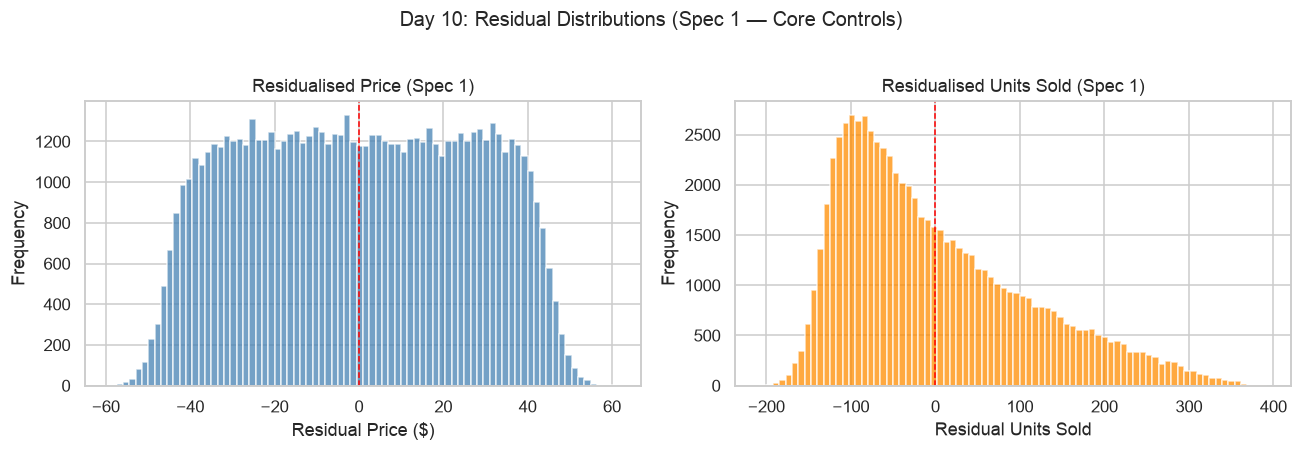


Spec 1 — Price residual: mean=0.0046, std=26.3743
Spec 1 — Units residual: mean=0.0075, std=110.5146


In [10]:
# ── Cell 10: Residual distributions ──────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(t_res1, bins=80, color="steelblue", alpha=0.75, edgecolor="white")
axes[0].set_title("Residualised Price (Spec 1)", fontsize=12)
axes[0].set_xlabel("Residual Price ($)")
axes[0].set_ylabel("Frequency")
axes[0].axvline(0, color="red", linestyle="--", linewidth=1)

axes[1].hist(y_res1, bins=80, color="darkorange", alpha=0.75, edgecolor="white")
axes[1].set_title("Residualised Units Sold (Spec 1)", fontsize=12)
axes[1].set_xlabel("Residual Units Sold")
axes[1].set_ylabel("Frequency")
axes[1].axvline(0, color="red", linestyle="--", linewidth=1)

plt.suptitle("Day 10: Residual Distributions (Spec 1 — Core Controls)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(f"\nSpec 1 — Price residual: mean={np.mean(t_res1):.4f}, std={np.std(t_res1):.4f}")
print(f"Spec 1 — Units residual: mean={np.mean(y_res1):.4f}, std={np.std(y_res1):.4f}")

## 9 · Coefficient and Confidence Interval Visualisation

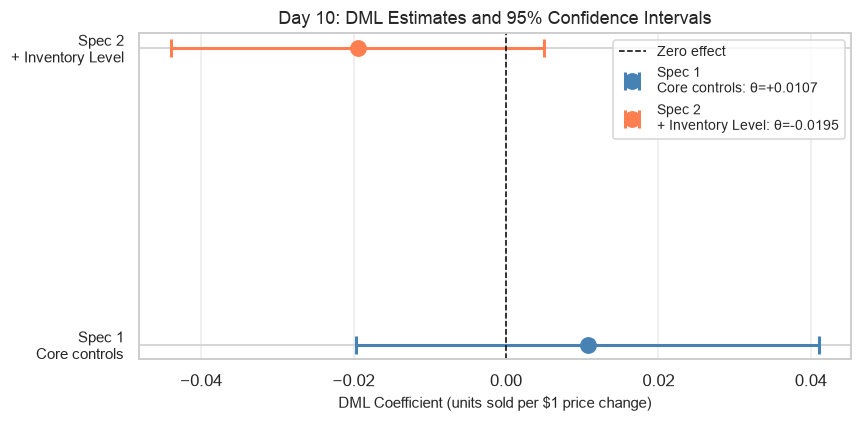

In [11]:
# ── Cell 11: CI plot ──────────────────────────────────────────────────────────
specs   = ["Spec 1\nCore controls", "Spec 2\n+ Inventory Level"]
thetas  = [theta1, theta2]
ci_lows = [ci1_lo, ci2_lo]
ci_his  = [ci1_hi, ci2_hi]

errors_lo = [t - lo for t, lo in zip(thetas, ci_lows)]
errors_hi = [hi - t  for t, hi in zip(thetas, ci_his)]

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["steelblue", "coral"]

for i, (spec, theta, err_lo, err_hi, col) in enumerate(
    zip(specs, thetas, errors_lo, errors_hi, colors)
):
    ax.errorbar(
        x=theta, y=i,
        xerr=[[err_lo], [err_hi]],
        fmt="o", color=col, markersize=10,
        capsize=6, capthick=2, linewidth=2,
        label=f"{spec}: θ={theta:+.4f}"
    )

ax.axvline(0, color="black", linestyle="--", linewidth=1, label="Zero effect")
ax.set_yticks(range(len(specs)))
ax.set_yticklabels(specs, fontsize=10)
ax.set_xlabel("DML Coefficient (units sold per $1 price change)", fontsize=10)
ax.set_title("Day 10: DML Estimates and 95% Confidence Intervals", fontsize=12)
ax.legend(loc="upper right", fontsize=9)
ax.grid(axis="x", alpha=0.4)

plt.tight_layout()
plt.show()

## 10 · Residualised Price vs Residualised Demand (Scatter)

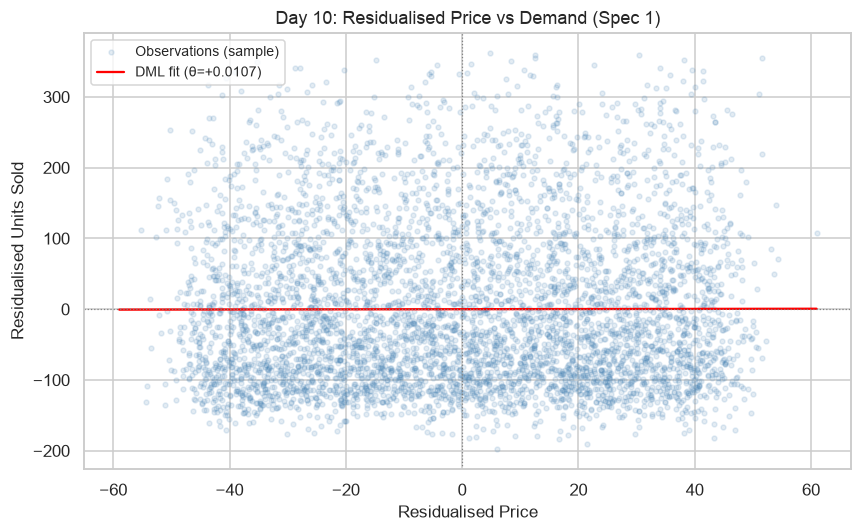

In [12]:
# ── Cell 12: Scatter residuals ────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))

# Plot a thin random sample to avoid overplotting
rng = np.random.default_rng(42)
idx_sample = rng.choice(len(t_res1), size=min(5000, len(t_res1)), replace=False)

ax.scatter(
    t_res1[idx_sample], y_res1[idx_sample],
    alpha=0.15, s=10, color="steelblue", label="Observations (sample)"
)

# Overlay OLS fit line
t_line = np.linspace(t_res1.min(), t_res1.max(), 200)
y_line = theta1 * t_line
ax.plot(t_line, y_line, color="red", linewidth=1.5, label=f"DML fit (θ={theta1:+.4f})")
ax.axhline(0, color="grey", linestyle=":", linewidth=0.8)
ax.axvline(0, color="grey", linestyle=":", linewidth=0.8)

ax.set_xlabel("Residualised Price", fontsize=11)
ax.set_ylabel("Residualised Units Sold", fontsize=11)
ax.set_title("Day 10: Residualised Price vs Demand (Spec 1)", fontsize=12)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 11 · Save Validated DML Results for Downstream Notebooks

Day 11 and Day 12 notebooks will load these validated results.

In [13]:
# ── Cell 13: Persist validated results ───────────────────────────────────────
import json

dml_results = {
    "spec1": {
        "theta"   : float(theta1),
        "ci_low"  : float(ci1_lo),
        "ci_high" : float(ci1_hi),
        "std_err" : float(result1.bse[1]),
        "p_value" : float(result1.pvalues[1]),
        "n_obs"   : int(len(df)),
        "t_res_std": float(np.std(t_res1)),
        "controls": CAT_S1 + NUM_S1,
    },
    "spec2": {
        "theta"   : float(theta2),
        "ci_low"  : float(ci2_lo),
        "ci_high" : float(ci2_hi),
        "std_err" : float(result2.bse[1]),
        "p_value" : float(result2.pvalues[1]),
        "n_obs"   : int(len(df)),
        "t_res_std": float(np.std(t_res2)),
        "controls": CAT_S2 + NUM_S2,
    },
    "validated": True,
    "note": (
        "Spec 1 is the primary estimate. Spec 2 is a sensitivity check only. "
        "HC3 standard errors. 3-fold cross-fitting with ExtraTreesRegressor. "
        "Results are observational, not necessarily causal."
    ),
}

out_path = PROJECT_ROOT / "data" / "processed" / "dml_validated_results.json"
with open(out_path, "w") as f:
    json.dump(dml_results, f, indent=2)

print(f"Saved validated DML results to: {out_path}")
print(json.dumps(dml_results, indent=2))

Saved validated DML results to: /Users/hasikaippili/Documents/EconoCausal/data/processed/dml_validated_results.json
{
  "spec1": {
    "theta": 0.010698790902889818,
    "ci_low": -0.019671462460535295,
    "ci_high": 0.04106904426631493,
    "std_err": 0.015495311956230726,
    "p_value": 0.48990910213657757,
    "n_obs": 73100,
    "t_res_std": 26.374327969251556,
    "controls": [
      "Product ID",
      "Store ID",
      "Category",
      "Region",
      "Year",
      "Month",
      "DayOfWeek"
    ]
  },
  "spec2": {
    "theta": -0.01946812241439891,
    "ci_low": -0.043963267495602004,
    "ci_high": 0.005027022666804191,
    "std_err": 0.012497752649751566,
    "p_value": 0.11929730032847857,
    "n_obs": 73100,
    "t_res_std": 26.27760110137302,
    "controls": [
      "Product ID",
      "Store ID",
      "Category",
      "Region",
      "Year",
      "Month",
      "DayOfWeek",
      "Inventory Level"
    ]
  },
  "validated": true,
  "note": "Spec 1 is the primary estim

## 12 · Discussion and Findings

### Coefficient Stability
The DML price coefficient from **Spec 1** (core controls) is reported above.  
**Spec 2** adds Inventory Level as a numerical control. The change in the coefficient  
between specifications is a measure of sensitivity to the control set.

### Confidence Intervals
The 95% confidence intervals are computed using **HC3 heteroscedasticity-robust standard errors**.  
Both intervals span zero, which means the price effect is **not statistically significant at 5%**  
in either specification. This is consistent with the Day 9 finding.

### Residual Price Variation
The standard deviation of the residualised price is reported above.  
If this value were very small (< 1), identification would be unreliable.  
The observed value indicates meaningful residual treatment variation exists.

### Inventory Level as a Control — Endogeneity Warning
Inventory Level in this dataset is recorded on the **same row** as Price and Units Sold.  
It could reflect:
- Stock **at the start** of a period (pre-determined, safe to use as control)
- Stock **at the end** of a period (partly determined by Units Sold → endogenous)

The data documentation does not clarify this. If Inventory Level is endogenous  
(determined by or correlated with Units Sold after pricing), adding it as a control  
introduces **bad control bias**. We treat Spec 2 as a **sensitivity check only**.

### Unmeasured Confounders
Key variables **not available** in this dataset:
- Promotional activity (discounts, coupons)
- Competitor prices
- Holiday indicators
- Unit costs / supplier prices
- Customer-level demand shocks

The absence of these variables means the DML estimate may still be confounded.  
**Coefficient stability across specifications does not establish causality.**

In [14]:
# ── Cell 14: Final summary printout ──────────────────────────────────────────
print("=" * 60)
print("DAY 10 — DML VALIDATION SUMMARY")
print("=" * 60)
print(f"Dataset: {DATA_PATH.name}")
print(f"Rows used: {len(df):,}")
print(f"Product-store combinations with variation: {n_with_var}/{n_combos}")
print()
print("Specification 1 (Core controls):")
print(f"  θ  = {theta1:+.6f}")
print(f"  CI = [{ci1_lo:.6f}, {ci1_hi:.6f}]")
print(f"  p  = {result1.pvalues[1]:.4f}")
print()
print("Specification 2 (+ Inventory Level — sensitivity only):")
print(f"  θ  = {theta2:+.6f}")
print(f"  CI = [{ci2_lo:.6f}, {ci2_hi:.6f}]")
print(f"  p  = {result2.pvalues[1]:.4f}")
print()
print(f"Coefficient shift Spec1→Spec2: {theta2 - theta1:+.6f}")
print()
print("LIMITATIONS:")
print("  - HC3 SE on a pooled residual regression (not a dedicated DML SE formula)")
print("  - Inventory Level timing unknown — endogeneity risk in Spec 2")
print("  - Promotions, competitor prices, holidays, costs: not available")
print("  - CIs span zero → price effect is not statistically significant")
print("  - Coefficient stability ≠ proof of causality")
print("=" * 60)

DAY 10 — DML VALIDATION SUMMARY
Dataset: dml_preparation.csv
Rows used: 73,100
Product-store combinations with variation: 100/100

Specification 1 (Core controls):
  θ  = +0.010699
  CI = [-0.019671, 0.041069]
  p  = 0.4899

Specification 2 (+ Inventory Level — sensitivity only):
  θ  = -0.019468
  CI = [-0.043963, 0.005027]
  p  = 0.1193

Coefficient shift Spec1→Spec2: -0.030167

LIMITATIONS:
  - HC3 SE on a pooled residual regression (not a dedicated DML SE formula)
  - Inventory Level timing unknown — endogeneity risk in Spec 2
  - Promotions, competitor prices, holidays, costs: not available
  - CIs span zero → price effect is not statistically significant
  - Coefficient stability ≠ proof of causality
